In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import xarray as xr
from extinction_compare_metrics import stat_dict

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
df = exset.to_dataframe(0.67, 'cloud', 'extinction')
df

,x,y,z,extinction,retrieval_root,retrieval_name
0,0.275,0.275,0.4,5.454699,/data/gdi/b/johntl3/LundstromPub2025/experimen...,aod0p150
1,0.275,0.275,0.5,0.872766,/data/gdi/b/johntl3/LundstromPub2025/experimen...,aod0p150
2,0.275,0.275,0.6,3.045300,/data/gdi/b/johntl3/LundstromPub2025/experimen...,aod0p150
3,0.275,0.275,0.7,1.694295,/data/gdi/b/johntl3/LundstromPub2025/experimen...,aod0p150
4,0.275,0.275,0.8,2.399685,/data/gdi/b/johntl3/LundstromPub2025/experimen...,aod0p150
...,...,...,...,...,...,...
42572,17.325,16.225,0.5,2.312398,/data/gdi/b/johntl3/LundstromPub2025/experimen...,CTP
42573,17.325,16.225,0.6,20.648478,/data/gdi/b/johntl3/LundstromPub2025/experimen...,CTP
42574,17.325,16.500,0.6,1.513914,/data/gdi/b/johntl3/LundstromPub2025/experimen...,CTP
42575,17.325,16.500,0.7,2.603225,/data/gdi/b/johntl3/LundstromPub2025/experimen...,CTP


In [5]:
cmap = {
    # 'in situ': 'lime',
    'default': 'tab:blue',
    # 'AT3D': 'tab:brown',
    'periodic': 'tab:orange',
    # 'open -> periodic': 'tab:blue',
    # 'unconstrained in cvm': 'tab:red',
    'unconstrained': 'tab:green',
    # 'constrained -> unconstrained in cvm': 'tab:red',
    # 'unconstrained out cvm': 'tab:pink',
    # 'constrained -> unconstrained out cvm': 'tab:pink',
    'aod0p150': 'tab:red',
    'aod0p250': 'tab:purple',
    # 'AOD 0.2 -> 0.15': 'tab:orange',
    'surf4p0': 'tab:brown',
    # 'surf. wind 0.67 m/s -> 4.0 m/s': 'tab:purple',
    'ATM': 'tab:pink',
    'ATP': 'tab:gray',
    'CTM': 'tab:olive',
    'CTP': 'tab:cyan'
}

In [6]:
cvm = exset.get_retrieval('default').cvm.cloud_volume_mask
cvm_vol = cvm.sum().data
cvm_nh = (cvm.integrate('z') > 0).sum().data

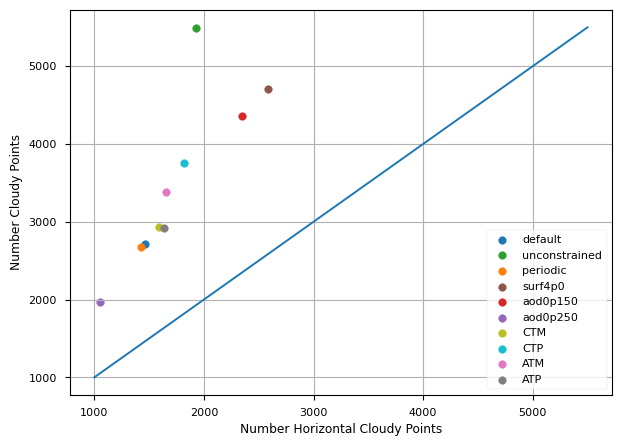

In [7]:
summary_counts = df.groupby(['retrieval_name'])['extinction'].agg(['count']).reset_index()
cf = []
for rn in summary_counts['retrieval_name']:
    cf.append(exset.get_retrieval(rn).calc_CF(0.67, 'cloud'))
summary_counts['cloud fraction'] = cf
summary_counts = summary_counts.set_index('retrieval_name')

f, ax = plt.subplots(1, 1, figsize=(7,5))
sublist = ['default', 'unconstrained', 'periodic', 'surf4p0', 'aod0p150', 'aod0p250', 'CTM', 'CTP', 'ATM', 'ATP']
for rn in sublist:
    ax.scatter(
        summary_counts.loc[rn, 'cloud fraction']*65**2,
        summary_counts.loc[rn, 'count'],
        label=rn,
        c=cmap[rn]
    )
# ax.scatter(cvm_nh, cvm_vol, c='k', label='cloud volume mask')
ax.legend()
ax.set_ylabel('Number Cloudy Points')
ax.set_xlabel('Number Horizontal Cloudy Points')
ax.grid()
ax.plot([1000, 5500], [1000, 5500])

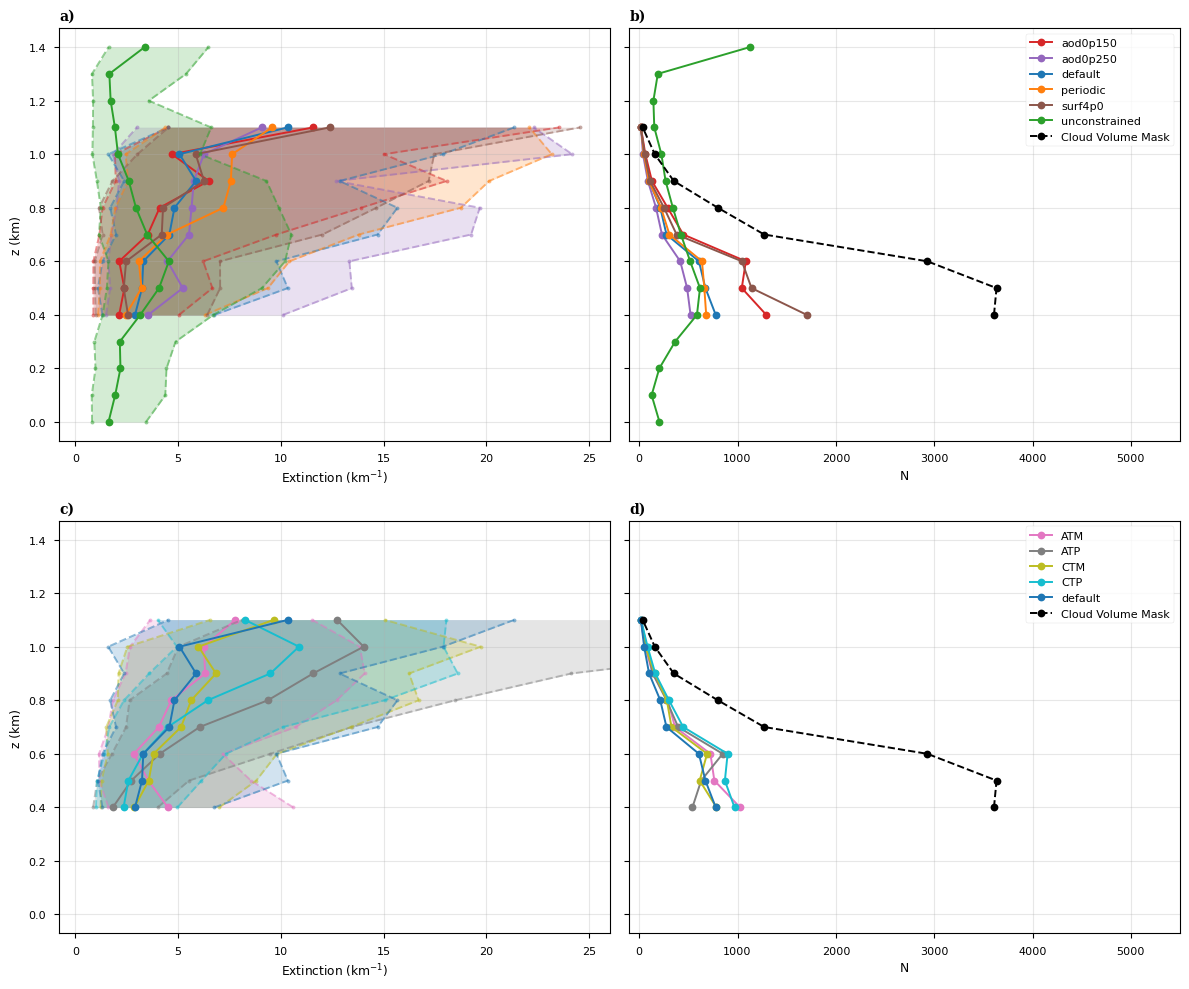

In [9]:
# Aggregate extinction at each z for each retrieval
l = 0.25
m = 0.5
h = 0.75
summary_quantiles = df.groupby(['retrieval_name', 'z'])['extinction'].quantile([l, m, h]).unstack().reset_index()
summary_counts = df.groupby(['retrieval_name', 'z'])['extinction'].agg(['count']).reset_index()
cvm = exset.get_retrieval('default').cvm.cloud_volume_mask.to_dataframe().reset_index()
cvm_counts = cvm[cvm['cloud_volume_mask'] == 1].groupby(['z'])['cloud_volume_mask'].agg(['count']).reset_index()

sublists = []
# sublists.append(['default', 'unconstrained', 'periodic', 'surf4p0', 'aod0p150', 'aod0p250', 'CTM', 'CTP', 'ATM', 'ATP'])
sublists.append(['default', 'unconstrained', 'periodic', 'surf4p0', 'aod0p150', 'aod0p250'])
sublists.append(['default', 'CTM', 'CTP', 'ATM', 'ATP'])
# sublists.append(['default', 'unconstrained'])
# sublists.append(['default', 'periodic'])
# sublists.append(['default', 'surf4p0'])
# sublists.append(['default', 'aod0p150', 'aod0p250'])
# sublists.append(['default', 'CTM', 'CTP'])
# sublists.append(['default', 'ATM', 'ATP'])

fig, ax = plt.subplots(len(sublists), 2, figsize=(12, len(sublists)*5), sharey=True)
j = 0
for i, sublist in enumerate(sublists):
    for retrieval_name, group in summary_quantiles.groupby('retrieval_name'):
        if(retrieval_name in sublist):
            group = group.sort_values('z')
            # c = f'C{j}'
            c = cmap[retrieval_name]
            ax[i, 0].plot(group[m], group['z'], label=retrieval_name, marker='o', c=c)
            ax[i, 0].plot(group[l], group['z'], marker='.', ls='--', c=c, alpha=0.5)
            ax[i, 0].plot(group[h], group['z'], marker='.', ls='--', c=c, alpha=0.5)

            ax[i, 0].fill_betweenx(group['z'], group[l], group[h], alpha=0.2, color=c)
            j += 1

    ax[i, 0].set_xlabel(r'Extinction (km$^{-1}$)')
    ax[i, 0].set_ylabel('z (km)')
    # ax[i, 0].legend()
    # ax[i, 0].set_xscale('log')
    ax[i, 0].grid(True, alpha=0.3)
    ax[i, 0].set_xlim([-0.8, 26])

    for retrieval_name, group in summary_counts.groupby('retrieval_name'):
        if(retrieval_name in sublist):
            group = group.sort_values('z')

            ax[i, 1].plot(group['count'], group['z'], label=retrieval_name, marker='o', c=cmap[retrieval_name])

    ax[i, 1].plot(cvm_counts['count'], cvm_counts['z'], label='Cloud Volume Mask', marker='o', c='k', ls='--')

    ax[i, 1].set_xlabel('N')
    # ax[i, 1].set_ylabel('z')
    ax[i, 1].legend()
    ax[i, 1].grid(True, alpha=0.3)
    ax[i, 1].set_xlim([-100, 5500])

set_labels(ax.flatten())
plt.tight_layout()